In [2]:
#주성분 분석
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()

columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

df = pd.DataFrame(iris.data, columns= columns)
df["target"] = iris.target
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


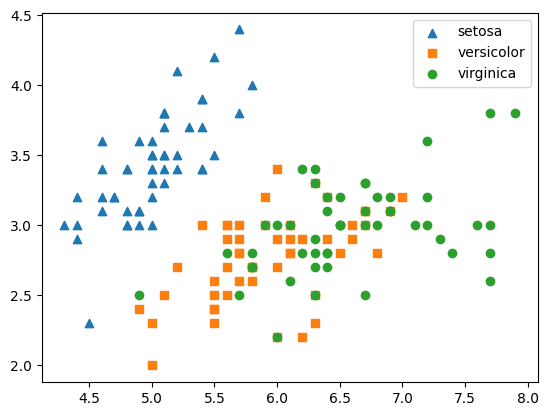

In [3]:
markers = ["^", "s", "o"]

for i , marker in enumerate(markers):
    x_axis_data = df[df["target"] == i]["sepal_length"]
    y_axis_data = df[df["target"] == i]["sepal_width"]
    plt.scatter(x_axis_data, y_axis_data, marker= marker, label = iris.target_names[i])

plt.legend()
plt.show()

In [4]:
from sklearn.preprocessing import StandardScaler

iris_scaled = StandardScaler().fit_transform(df.iloc [ :,:-1])

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components= 2)

pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)
print(iris_pca.shape)



(150, 2)


In [6]:
pca_columns = ["pca_component_1", "pca_component_2"]
df_pca = pd.DataFrame(iris_pca, columns= pca_columns)

df_pca["target"] = iris.target
df_pca.head()

,pca_component_1,pca_component_2,target
0,-2.264703,0.480027,0
1,-2.080961,-0.674134,0
2,-2.364229,-0.341908,0
3,-2.299384,-0.597395,0
4,-2.389842,0.646835,0


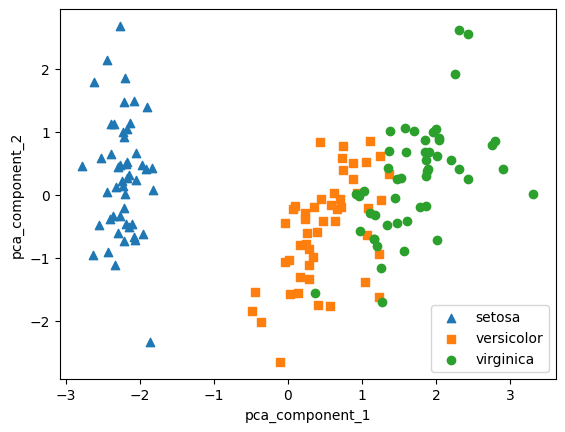

In [7]:
markers = ["^", "s", "o"]

for i, marker in enumerate(markers):
    x_axis_data = df_pca[df_pca["target"] == i]["pca_component_1"]
    y_axis_data = df_pca[df_pca["target"] == i]["pca_component_2"]
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend()
plt.xlabel("pca_component_1")
plt.ylabel("pca_component_2")
plt.show()

In [8]:
print(pca.explained_variance_ratio_)

[0.72962445 0.22850762]


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

rfc = RandomForestClassifier(random_state= 156)
scores = cross_val_score(rfc, iris.data, iris.target, scoring = "accuracy" , cv =3)

print("개별", scores)
print("평균정확도", np.mean(scores))

개별 [0.98 0.94 0.96]
평균정확도 0.96


In [10]:
pca_X = df_pca[["pca_component_1", "pca_component_2"]]
scores_pca = cross_val_score(
    rfc, pca_X, iris.target, scoring="accuracy", cv=3
)

print( "개별", scores_pca)
print("평균정확도 ", np.mean(scores_pca))

개별 [0.88 0.88 0.88]
평균정확도  0.88


In [11]:
import pandas as pd
df = pd.read_excel("./pca_credit_card.xls", header=1 , sheet_name = "Data").iloc[0:,1:]
print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [12]:
df.rename(columns={"PAY_0":"PAY_1", "default payment next month" : "default"}, inplace=True)

y_target = df["default"]
X_features= df.drop("default",axis =1)

In [13]:
X_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

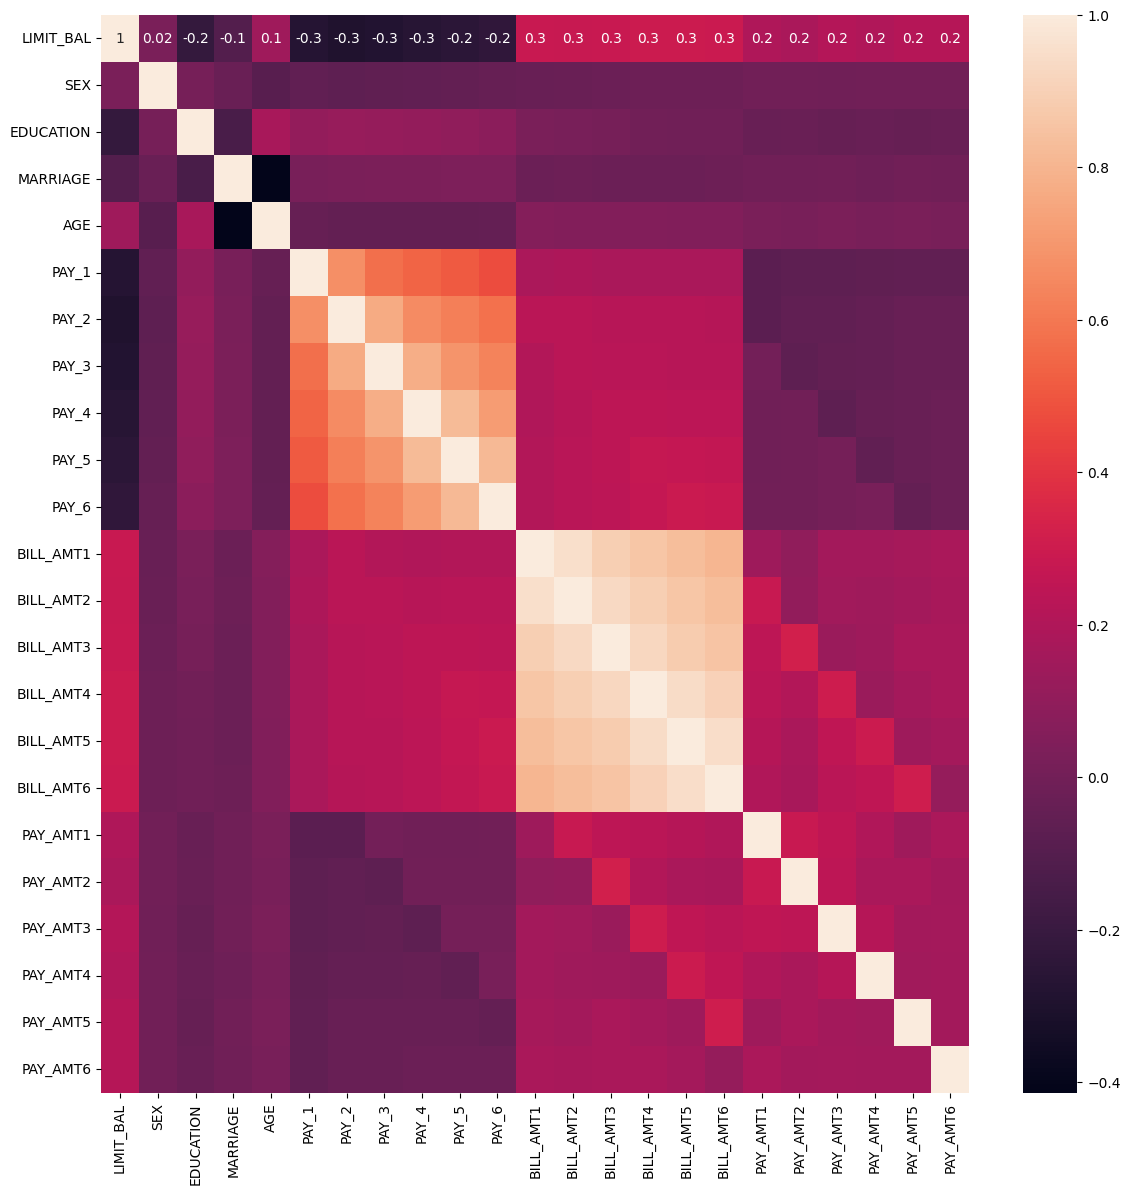

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
corr = X_features.corr(numeric_only=True)

plt.figure(figsize=(14, 14))
sns.heatmap(corr, annot=True, fmt=".1g")
plt.show()

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols_bill = ["BILL_AMT"+str(i) for i in range(1,7)]
cols_pay = ["PAY_"+str(i) for i in range(1,7)]
cols_amt = ["PAY_AMT" + str(i) for i in range(1,7)]

print(cols_bill)
cols_bill.extend(cols_pay)
cols_bill.extend(cols_amt)
print("대상 속성 명 : ", cols_bill)

['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
대상 속성 명 :  ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [16]:
scaler = StandardScaler()
X_bill_scaled = scaler.fit_transform(X_features[cols_bill])

pca = PCA(n_components=2)
X_bill_pca = pca.fit_transform(X_bill_scaled)

print("설명 분산 비율:", pca.explained_variance_ratio_)

설명 분산 비율: [0.36180187 0.20618472]


In [17]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rfc = RandomForestClassifier(n_estimators=300, random_state=156)
scores = cross_val_score(
    rfc, X_features, y_target, scoring="accuracy", cv=3
)

print("교차 검증 정확도:", scores)
print("평균 정확도:", np.mean(scores))

교차 검증 정확도: [0.8083 0.8196 0.8232]
평균 정확도: 0.8170333333333333


In [18]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(X_features)

pca = PCA(n_components=6)
df_pca = pca.fit_transform(df_scaled)

scores_pca = cross_val_score(
    rfc, df_pca, y_target, scoring="accuracy", cv=3
)

print("PCA 변환 후 교차 검증 정확도:", scores_pca)
print("PCA 변환 후 평균 정확도:", np.mean(scores_pca))

PCA 변환 후 교차 검증 정확도: [0.7906 0.796  0.8019]
PCA 변환 후 평균 정확도: 0.7961666666666667
